# 03 - Descriptive Statistics

## Objective
This notebook performs descriptive statistical analysis to address SOP 1 and SOP 2.

## Statistical Procedures

### SOP 1 - Predictor Variables
1. Calculate the mean and standard deviation of the six predictor construct scores.
2. Assign verbal interpretations based on the established five-point scale.
3. Generate a summary table and bar chart.

### SOP 2 - AI Adoption
1. Calculate the mean and standard deviation of the overall AI Adoption Score.
2. Determine the frequency and percentage of responses for each of the seven academic activities.
3. Calculate the mean usage frequency for each activity.
4. Generate tables and visualizations.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Define Project Paths

In [2]:
cwd = Path.cwd()

project_candidates = [cwd, cwd.parent]

PROJECT_ROOT = next(
    (
        path
        for path in project_candidates
        if (path / "requirements.txt").is_file()
    ),
    cwd,
)

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"

TABLES_DIR = RESULTS_DIR / "tables"
GRAPHS_DIR = RESULTS_DIR / "graphs"

INPUT_PATH = DATA_DIR / "scored_data.csv"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project directory: {PROJECT_ROOT}")
print(f"Input file: {INPUT_PATH}")
print(f"Tables directory: {TABLES_DIR}")
print(f"Graphs directory: {GRAPHS_DIR}")

Project directory: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis
Input file: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\data\scored_data.csv
Tables directory: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\tables
Graphs directory: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\graphs


## Load the Scored Dataset

In [3]:
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f"Scored dataset not found: {INPUT_PATH}. "
        "Run 02_scoring.ipynb first."
    )

df = pd.read_csv(INPUT_PATH)

print(f"Loaded {len(df):,} respondent(s).")
print(f"Dataset shape: {df.shape}")

display(df.head())

Loaded 100 respondent(s).
Dataset shape: (100, 34)


,ai_familiarity_main_functions,ai_familiarity_tool_availability,ai_familiarity_task_fit,perceived_usefulness_concept_understanding,perceived_usefulness_task_efficiency,perceived_usefulness_work_quality,perceived_ease_learning,perceived_ease_academic_tasks,perceived_ease_useful_responses,trust_information_dependability,...,adoption_plan_research,trust_accuracy_concern_reversed,accessibility_cost_barrier_reversed,ai_familiarity_score,perceived_usefulness_score,perceived_ease_of_use_score,trust_score,accessibility_score,digital_literacy_score,ai_adoption_score
0,4,3,4,4,4,4,4,3,3,2,...,0,1,3,3.666667,4.000000,3.333333,2.333333,3.333333,4.333333,0.714286
1,5,5,5,5,5,5,5,5,5,4,...,2,2,1,5.000000,5.000000,5.000000,3.666667,3.666667,4.666667,3.285714
2,4,4,4,4,4,4,4,4,4,4,...,2,2,3,4.000000,4.000000,4.000000,3.333333,4.333333,3.666667,2.571429
3,5,5,3,2,4,1,5,5,2,1,...,1,1,1,4.333333,2.333333,4.000000,1.000000,3.666667,3.333333,2.857143
4,4,4,5,4,5,5,4,4,4,4,...,3,3,2,4.333333,4.666667,4.000000,3.666667,3.333333,4.000000,3.000000


## Define Analysis Columns

In [4]:
construct_columns = {
    "AI Familiarity": "ai_familiarity_score",
    "Perceived Usefulness": "perceived_usefulness_score",
    "Perceived Ease of Use": "perceived_ease_of_use_score",
    "Trust": "trust_score",
    "Accessibility": "accessibility_score",
    "Digital Literacy": "digital_literacy_score",
}

adoption_column = "ai_adoption_score"

activity_columns = {
    "Understanding academic concepts": "adoption_explain_concepts",
    "Summarizing course materials": "adoption_summarize_materials",
    "Brainstorming academic ideas": "adoption_brainstorm_ideas",
    "Academic writing support": "adoption_writing_support",
    "Creating study materials": "adoption_create_study_materials",
    "Solving academic problems": "adoption_solve_problems",
    "Planning research tasks": "adoption_plan_research",
}

analysis_columns = (
    list(construct_columns.values())
    + [adoption_column]
    + list(activity_columns.values())
)

missing_columns = [
    column
    for column in analysis_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required analysis columns are missing: {missing_columns}"
    )

print(f"Predictor constructs: {len(construct_columns)}")
print(f"AI Adoption activities: {len(activity_columns)}")

Predictor constructs: 6
AI Adoption activities: 7


## Validate Analysis Data

In [5]:
validation_results = []

for label, column in construct_columns.items():
    values = pd.to_numeric(df[column], errors="coerce")

    validation_results.append({
        "variable": label,
        "missing_values": values.isna().sum(),
        "invalid_values": (
            ~values.between(1, 5) & values.notna()
        ).sum(),
    })

for label, column in {
    "AI Adoption Score": adoption_column,
    **activity_columns,
}.items():
    values = pd.to_numeric(df[column], errors="coerce")

    validation_results.append({
        "variable": label,
        "missing_values": values.isna().sum(),
        "invalid_values": (
            ~values.between(0, 5) & values.notna()
        ).sum(),
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

if (
    validation_df["missing_values"].sum() > 0
    or validation_df["invalid_values"].sum() > 0
):
    raise ValueError(
        "Data validation failed. Review missing or invalid values "
        "before proceeding."
    )

print("All analysis variables passed validation.")

,variable,missing_values,invalid_values
0,AI Familiarity,0,0
1,Perceived Usefulness,0,0
2,Perceived Ease of Use,0,0
3,Trust,0,0
4,Accessibility,0,0
5,Digital Literacy,0,0
6,AI Adoption Score,0,0
7,Understanding academic concepts,0,0
8,Summarizing course materials,0,0
9,Brainstorming academic ideas,0,0


All analysis variables passed validation.


## Define Predictor Interpretation Ranges

The five-point Likert scale uses the following equal-interval ranges:

| Mean Range | Interpretation |
|---|---|
| 4.21–5.00 | Very High |
| 3.41–4.20 | High |
| 2.61–3.40 | Moderate |
| 1.81–2.60 | Low |
| 1.00–1.80 | Very Low |

In [6]:
def interpret_likert_mean(score):
    if score <= 1.80:
        return "Very Low"
    if score <= 2.60:
        return "Low"
    if score <= 3.40:
        return "Moderate"
    if score <= 4.20:
        return "High"
    return "Very High"

## Calculate SOP 1 Descriptive Statistics

Calculate the mean and sample standard deviation of each predictor construct.

The mean represents the average respondent score, while the standard deviation describes how much the scores vary among respondents.

Assign a verbal interpretation to each construct based on its mean.

In [7]:
sop1_results = []

for construct, column in construct_columns.items():
    scores = df[column]

    mean_score = scores.mean()
    standard_deviation = scores.std(ddof=1)

    sop1_results.append({
        "Construct": construct,
        "Mean": mean_score,
        "Standard Deviation": standard_deviation,
        "Interpretation": interpret_likert_mean(mean_score),
        "Number of Respondents": scores.count(),
    })

sop1_df = pd.DataFrame(sop1_results)

display(
    sop1_df.style.format({
        "Mean": "{:.2f}",
        "Standard Deviation": "{:.2f}",
    })
)

,Construct,Mean,Standard Deviation,Interpretation,Number of Respondents
0,AI Familiarity,3.81,0.76,High,100
1,Perceived Usefulness,3.80,0.84,High,100
2,Perceived Ease of Use,3.67,0.87,High,100
3,Trust,3.00,0.72,Moderate,100
4,Accessibility,3.30,0.66,Moderate,100
5,Digital Literacy,3.72,0.72,High,100


## Export SOP 1 Statistics

In [8]:
sop1_path = TABLES_DIR / "sop1_construct_statistics.csv"

sop1_df.to_csv(sop1_path, index=False)

print(f"SOP 1 statistics exported to: {sop1_path}")

SOP 1 statistics exported to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\tables\sop1_construct_statistics.csv


## Visualize Predictor Construct Means

Create a bar chart showing the mean score of each predictor construct.

The chart uses the five-point Likert scale, with a reference line at the overall midpoint of 3.00.

Each bar represents the average score of one construct.

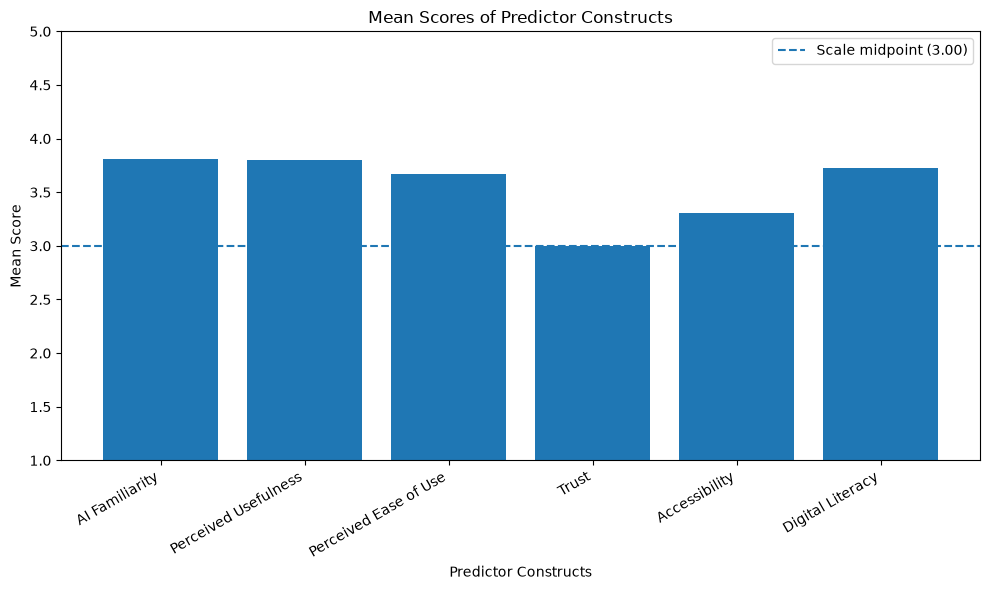

Graph saved to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\graphs\predictor_construct_means.png


In [9]:
plt.figure(figsize=(10, 6))

plt.bar(
    sop1_df["Construct"],
    sop1_df["Mean"],
)

plt.axhline(
    y=3,
    linestyle="--",
    label="Scale midpoint (3.00)",
)

plt.ylim(1, 5)
plt.ylabel("Mean Score")
plt.xlabel("Predictor Constructs")
plt.title("Mean Scores of Predictor Constructs")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()

sop1_graph_path = GRAPHS_DIR / "predictor_construct_means.png"

plt.savefig(
    sop1_graph_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(f"Graph saved to: {sop1_graph_path}")

## 10. Define AI Adoption Interpretation Ranges

Define the verbal interpretation categories for the overall AI Adoption Score.

The score ranges from 0 to 5 and uses six equal-interval categories:

| Mean Range | Interpretation |
|---|---|
| 4.17–5.00 | Very Frequent Use |
| 3.33–4.16 | Frequent Use |
| 2.50–3.32 | Moderately Frequent Use |
| 1.67–2.49 | Infrequent Use |
| 0.84–1.66 | Rare Use |
| 0.00–0.83 | No or Almost No Use |

The classification is based on the average of the seven activity-frequency scores. It does not mean that every activity has the same usage frequency.

In [10]:
def interpret_adoption_mean(score):
    if score <= 5 / 6:
        return "No or Almost No Use"
    if score <= 10 / 6:
        return "Rare Use"
    if score <= 2.50:
        return "Infrequent Use"
    if score <= 20 / 6:
        return "Moderately Frequent Use"
    if score <= 25 / 6:
        return "Frequent Use"
    return "Very Frequent Use"

## Calculate SOP 2 Overall AI Adoption Statistics

Calculate the mean and sample standard deviation of the AI Adoption Score across all respondents.

Assign a verbal interpretation based on the established frequency ranges.

In [11]:
adoption_scores = df[adoption_column]

adoption_mean = adoption_scores.mean()
adoption_std = adoption_scores.std(ddof=1)

sop2_overall_df = pd.DataFrame([{
    "Variable": "AI Adoption Score",
    "Mean": adoption_mean,
    "Standard Deviation": adoption_std,
    "Interpretation": interpret_adoption_mean(adoption_mean),
    "Number of Respondents": adoption_scores.count(),
}])

display(
    sop2_overall_df.style.format({
        "Mean": "{:.2f}",
        "Standard Deviation": "{:.2f}",
    })
)

,Variable,Mean,Standard Deviation,Interpretation,Number of Respondents
0,AI Adoption Score,2.88,0.90,Moderately Frequent Use,100


## Export Overall AI Adoption Statistics

In [12]:
sop2_overall_path = TABLES_DIR / "sop2_ai_adoption_statistics.csv"

sop2_overall_df.to_csv(sop2_overall_path, index=False)

print(f"Overall adoption statistics exported to: {sop2_overall_path}")

Overall adoption statistics exported to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\tables\sop2_ai_adoption_statistics.csv


## Visualize AI Adoption Score Distribution

Create a histogram showing the distribution of the overall AI Adoption Scores among respondents.

The histogram uses ten equal-width intervals across the 0–5 score range. A vertical reference line indicates the overall mean.

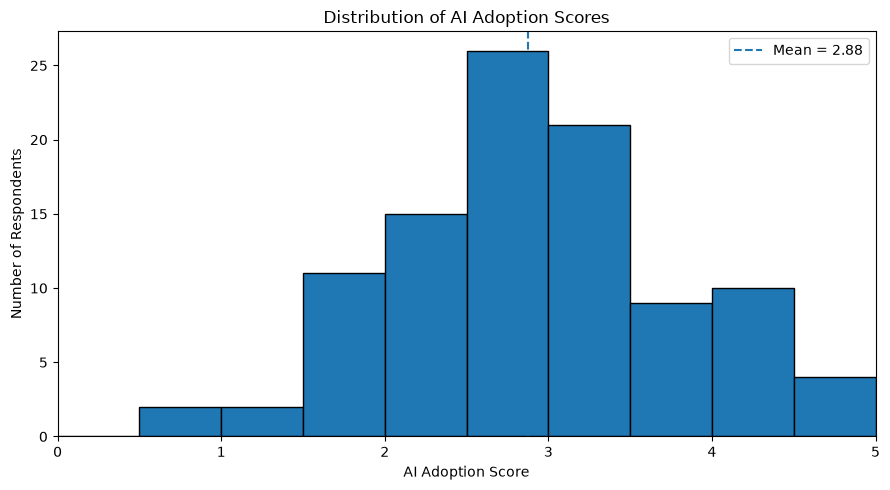

Graph saved to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\graphs\ai_adoption_score_distribution.png


In [13]:
plt.figure(figsize=(9, 5))

plt.hist(
    adoption_scores,
    bins=np.linspace(0, 5, 11),
    edgecolor="black",
)

plt.axvline(
    adoption_mean,
    linestyle="--",
    label=f"Mean = {adoption_mean:.2f}",
)

plt.xlim(0, 5)
plt.xlabel("AI Adoption Score")
plt.ylabel("Number of Respondents")
plt.title("Distribution of AI Adoption Scores")
plt.legend()
plt.tight_layout()

adoption_graph_path = GRAPHS_DIR / "ai_adoption_score_distribution.png"

plt.savefig(
    adoption_graph_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(f"Graph saved to: {adoption_graph_path}")

## Define Activity Frequency Categories

Define the six response categories used in the AI Adoption section.

These categories will be used to calculate the number and percentage of respondents who selected each frequency option for every academic activity.

In [14]:
frequency_categories = {
    0: "Never",
    1: "Once",
    2: "Two or three times",
    3: "About once a week",
    4: "Several times a week",
    5: "Daily or almost daily",
}

## Calculate Activity Frequency Distributions

Calculate the frequency and percentage of responses for each of the seven academic activities.

Each activity will have six frequency categories, from Never to Daily or almost daily.

Percentages are calculated using the total number of valid respondents for each activity.

In [15]:
activity_results = []

for activity, column in activity_columns.items():
    counts = (
        df[column]
        .value_counts()
        .reindex(frequency_categories.keys(), fill_value=0)
        .sort_index()
    )

    total_responses = counts.sum()

    for score, frequency_label in frequency_categories.items():
        count = counts.loc[score]
        percentage = (count / total_responses) * 100

        activity_results.append({
            "Academic Activity": activity,
            "Frequency Category": frequency_label,
            "Frequency Score": score,
            "Frequency": count,
            "Percentage": percentage,
        })

activity_frequency_df = pd.DataFrame(activity_results)

display(
    activity_frequency_df.style.format({
        "Percentage": "{:.2f}%",
    })
)

,Academic Activity,Frequency Category,Frequency Score,Frequency,Percentage
0,Understanding academic concepts,Never,0,4,4.00%
1,Understanding academic concepts,Once,1,13,13.00%
2,Understanding academic concepts,Two or three times,2,12,12.00%
3,Understanding academic concepts,About once a week,3,21,21.00%
4,Understanding academic concepts,Several times a week,4,38,38.00%
5,Understanding academic concepts,Daily or almost daily,5,12,12.00%
6,Summarizing course materials,Never,0,10,10.00%
7,Summarizing course materials,Once,1,8,8.00%
8,Summarizing course materials,Two or three times,2,19,19.00%
9,Summarizing course materials,About once a week,3,25,25.00%


## Export Activity Frequency Distribution

In [16]:
activity_frequency_path = (
    TABLES_DIR / "sop2_activity_frequency_distribution.csv"
)

activity_frequency_df.to_csv(
    activity_frequency_path,
    index=False,
)

print(f"Activity frequency table exported to: {activity_frequency_path}")

Activity frequency table exported to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\tables\sop2_activity_frequency_distribution.csv


## Visualize Activity Frequency Distributions

Create a horizontal stacked bar chart showing the percentage distribution of frequency responses for each academic activity.

Each bar represents one activity, while its segments represent the six frequency categories.

The percentages make it easier to compare usage patterns across different academic activities.

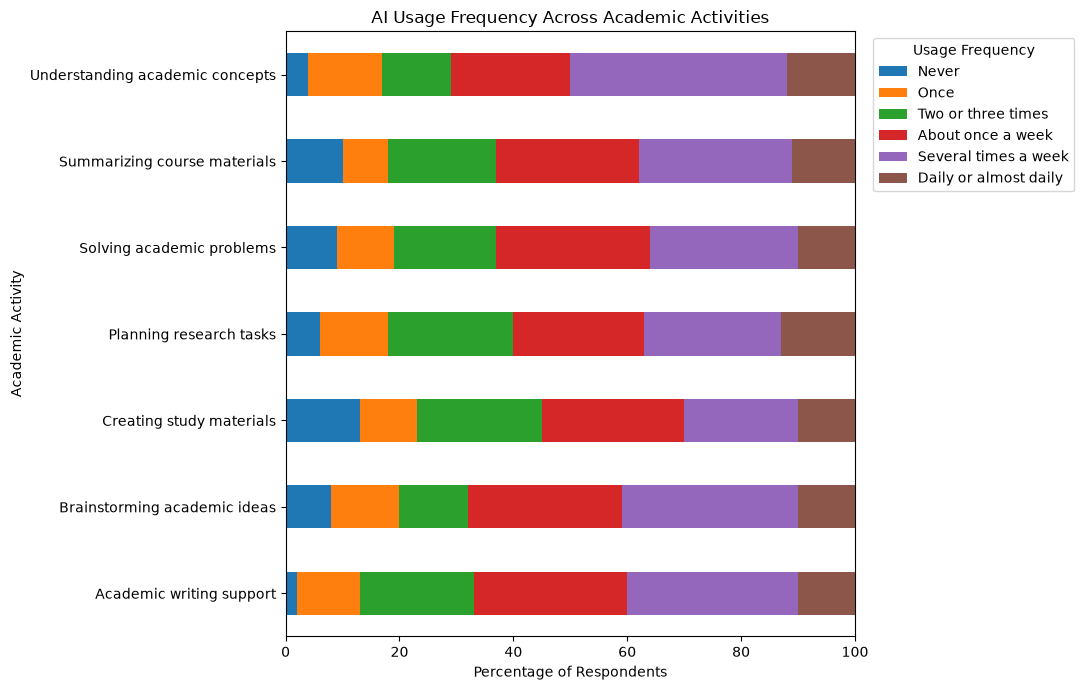

Graph saved to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\graphs\activity_frequency_distribution.png


In [17]:
plot_data = (
    activity_frequency_df
    .pivot(
        index="Academic Activity",
        columns="Frequency Category",
        values="Percentage",
    )
    .reindex(columns=list(frequency_categories.values()))
)

ax = plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 7),
)

ax.set_xlabel("Percentage of Respondents")
ax.set_ylabel("Academic Activity")
ax.set_title("AI Usage Frequency Across Academic Activities")
ax.legend(
    title="Usage Frequency",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.xlim(0, 100)
plt.tight_layout()

activity_graph_path = (
    GRAPHS_DIR / "activity_frequency_distribution.png"
)

plt.savefig(
    activity_graph_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(f"Graph saved to: {activity_graph_path}")

## Calculate Mean Frequency per Academic Activity

Calculate the mean and standard deviation of the coded frequency responses for each academic activity.

These statistics provide an additional summary of which academic activities are used more frequently.

The mean is based on the numerical frequency codes from 0 to 5, not an exact count of AI uses.

In [18]:
activity_mean_results = []

for activity, column in activity_columns.items():
    activity_mean_results.append({
        "Academic Activity": activity,
        "Mean Frequency Score": df[column].mean(),
        "Standard Deviation": df[column].std(ddof=1),
    })

activity_mean_df = pd.DataFrame(activity_mean_results)

display(
    activity_mean_df.style.format({
        "Mean Frequency Score": "{:.2f}",
        "Standard Deviation": "{:.2f}",
    })
)

,Academic Activity,Mean Frequency Score,Standard Deviation
0,Understanding academic concepts,3.12,1.37
1,Summarizing course materials,2.84,1.45
2,Brainstorming academic ideas,2.91,1.43
3,Academic writing support,3.02,1.24
4,Creating study materials,2.59,1.50
5,Solving academic problems,2.81,1.43
6,Planning research tasks,2.86,1.41


## Export Activity Mean Scores

In [19]:
activity_mean_path = TABLES_DIR / "sop2_activity_mean_frequency.csv"

activity_mean_df.to_csv(
    activity_mean_path,
    index=False,
)

print(f"Activity mean table exported to: {activity_mean_path}")

Activity mean table exported to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\tables\sop2_activity_mean_frequency.csv


## Visualize Mean Activity Frequency

Create a horizontal bar chart comparing the mean frequency score of each academic activity.

The scale ranges from 0 to 5, where higher values indicate more frequent reported use.

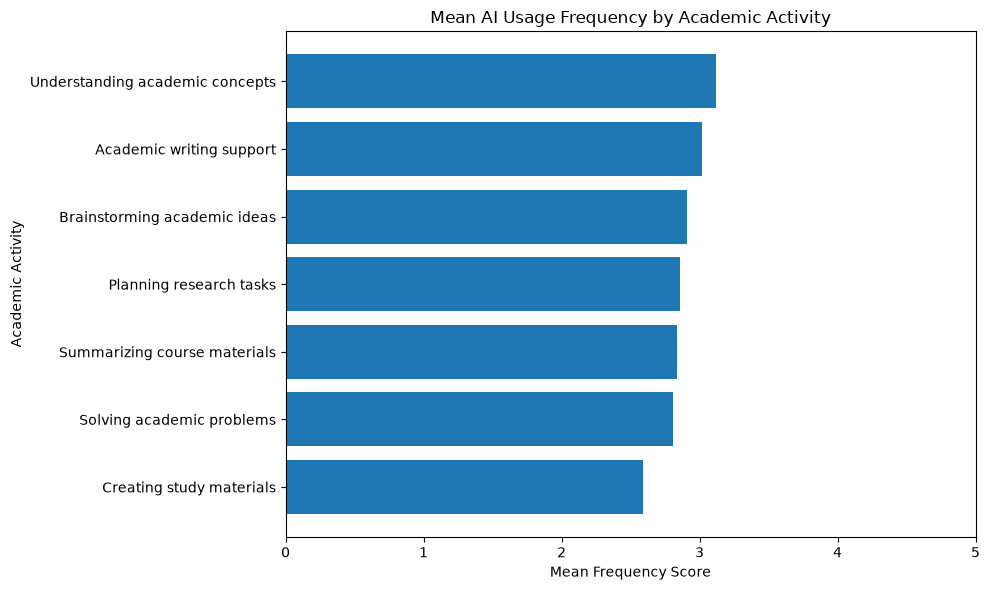

Graph saved to: c:\Users\julie\Downloads\IS_Research\ai-adoption-analysis\results\graphs\activity_mean_frequency.png


In [20]:
activity_plot_df = activity_mean_df.sort_values(
    "Mean Frequency Score"
)

plt.figure(figsize=(10, 6))

plt.barh(
    activity_plot_df["Academic Activity"],
    activity_plot_df["Mean Frequency Score"],
)

plt.xlim(0, 5)
plt.xlabel("Mean Frequency Score")
plt.ylabel("Academic Activity")
plt.title("Mean AI Usage Frequency by Academic Activity")
plt.tight_layout()

activity_mean_graph_path = (
    GRAPHS_DIR / "activity_mean_frequency.png"
)

plt.savefig(
    activity_mean_graph_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(f"Graph saved to: {activity_mean_graph_path}")

## Review Generated Outputs

In [21]:
print("Generated tables:")

for path in sorted(TABLES_DIR.glob("*.csv")):
    print(f"- {path.name}")

print("\nGenerated graphs:")

for path in sorted(GRAPHS_DIR.glob("*.png")):
    print(f"- {path.name}")

Generated tables:
- mlp_results.csv
- mlr_coefficients.csv
- model_comparison.csv
- regression_results.csv
- sop1_construct_statistics.csv
- sop2_activity_frequency_distribution.csv
- sop2_activity_mean_frequency.csv
- sop2_ai_adoption_statistics.csv

Generated graphs:
- activity_frequency_distribution.png
- activity_mean_frequency.png
- ai_adoption_score_distribution.png
- mlp_actual_vs_predicted.png
- model_comparison.png
- predictor_construct_means.png
- regression_actual_vs_predicted.png
